In [1]:
# ==========================================
# 1. SETUP & LIBRARIES
# ==========================================
!pip install timm -q
!pip install torch-summary -q

import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torch.optim as optim
import torchaudio
import torchaudio.transforms as T
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import f1_score, confusion_matrix, classification_report
import timm
from tqdm.notebook import tqdm
import warnings

warnings.filterwarnings('ignore')

# --- CONFIGURATION ---
CFG = {
    'root_dir': '/kaggle/input/intelecta-final-dataset/dataset_siap_pakai/dataset_siap_pakai',
    'sample_rate': 32000,
    'duration': 5,          
    'n_fft': 2048,
    'hop_length': 512,
    'n_mels': 256,
    'f_min': 0,
    'f_max': 16000,
    'model_name': 'tf_efficientnet_b2_ns',
    'image_size': 260,
    'num_classes': 31,
    'batch_size': 16,
    'epochs': 30,
    'lr': 1e-3,
    'weight_decay': 1e-4,
    'mixup_alpha': 0.2,
    'label_smoothing': 0.1,
    'seed': 42,
    'device': 'cuda' if torch.cuda.is_available() else 'cpu',
    'target_fold': 0
}

def seed_everything(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed(seed)
    torch.backends.cudnn.deterministic = True

seed_everything(CFG['seed'])
print(f"✅ Configuration Ready. Using {CFG['model_name']} on {CFG['device']}")

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 4.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 90.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 73.1 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 43.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.4 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 1.9 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 29.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 13.1 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 207.5/207.5 MB 8.2 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 21.1/21.1 MB 77.2 MB/s eta 0:00:00:00:0100:01
ERROR: pip's dependency resolver does not currently take into account all the packages that are installe

/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

✅ Configuration Ready. Using tf_efficientnet_b2_ns on cuda


In [2]:
# ==========================================
# 2. DATA PREPARATION (NORMAL STRATIFIED GROUP K-FOLD)
# ==========================================
data = []
train_dir = os.path.join(CFG['root_dir'], 'train')

for label in sorted(os.listdir(train_dir)):
    label_dir = os.path.join(train_dir, label)
    if os.path.isdir(label_dir):
        for f in os.listdir(label_dir):
            if f.endswith('.wav'):
                group_id = f.rsplit('_', 1)[0]
                data.append({
                    'filename': f,
                    'label': label,
                    'path': os.path.join(label_dir, f),
                    'group_id': group_id
                })

df = pd.DataFrame(data)

# Mapping Labels
classes = sorted(df['label'].unique())
label2id = {k: v for v, k in enumerate(classes)}
id2label = {v: k for k, v in label2id.items()}
df['label_id'] = df['label'].map(label2id)

# Class Weights
class_counts = df['label_id'].value_counts().sort_index()
weights = 1.0 / class_counts
weights = weights / weights.sum() * len(classes)
class_weights = torch.tensor(weights.values, dtype=torch.float).to(CFG['device'])

# Normal Stratified Group K-Fold (Membiarkan Weddell Seal terdistribusi alami)
sgkf = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=CFG['seed'])
df['fold'] = -1
for fold, (train_idx, val_idx) in enumerate(sgkf.split(df, df['label_id'], df['group_id'])):
    df.loc[val_idx, 'fold'] = fold

print(f"✅ Data Loaded: {len(df)} samples.")
print(f"✅ Imbalance Handling: Class Weights Calculated.")
print(f"✅ Split: Stratified Group K-Fold Applied (Standard).")

✅ Data Loaded: 1357 samples.
✅ Imbalance Handling: Class Weights Calculated.
✅ Split: Stratified Group K-Fold Applied (Standard).


In [3]:
# ==========================================
# 3. HIGH-FIDELITY DATASET
# ==========================================
class HighFidelityAudioDataset(Dataset):
    def __init__(self, df, is_train=False):
        self.df = df
        self.is_train = is_train
        
        self.mel_spec = T.MelSpectrogram(
            sample_rate=CFG['sample_rate'],
            n_fft=CFG['n_fft'],
            hop_length=CFG['hop_length'],
            n_mels=CFG['n_mels'],
            f_min=CFG['f_min'],
            f_max=CFG['f_max']
        )
        self.to_db = T.AmplitudeToDB()
        
        self.spec_aug = torch.nn.Sequential(
            T.FrequencyMasking(freq_mask_param=25),
            T.TimeMasking(time_mask_param=70)
        )

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        waveform, sr = torchaudio.load(row['path'])
        
        if sr != CFG['sample_rate']:
            waveform = T.Resample(sr, CFG['sample_rate'])(waveform)
            
        target_len = CFG['sample_rate'] * CFG['duration']
        if waveform.shape[1] < target_len:
            repeat = (target_len // waveform.shape[1]) + 1
            waveform = waveform.repeat(1, repeat)[:, :target_len]
        elif waveform.shape[1] > target_len:
            if self.is_train:
                start = torch.randint(0, waveform.shape[1] - target_len, (1,)).item()
            else:
                start = (waveform.shape[1] - target_len) // 2
            waveform = waveform[:, start:start+target_len]

        spec = self.mel_spec(waveform)
        spec = self.to_db(spec)
        
        if self.is_train:
            spec = self.spec_aug(spec)

        spec = (spec - spec.min()) / (spec.max() - spec.min() + 1e-6)

        spec = torch.nn.functional.interpolate(
            spec.unsqueeze(0), 
            size=(CFG['image_size'], CFG['image_size']), 
            mode='bilinear', align_corners=False
        ).squeeze(0)
        
        spec = spec.expand(3, -1, -1)

        return spec, torch.tensor(row['label_id'], dtype=torch.long)

In [4]:
# ==========================================
# 4. UTILS: MIXUP & MODEL ARCHITECTURE
# ==========================================
def mixup_data(x, y, alpha=0.2):
    if alpha > 0: lam = np.random.beta(alpha, alpha)
    else: lam = 1
    index = torch.randperm(x.size()[0]).to(CFG['device'])
    mixed_x = lam * x + (1 - lam) * x[index, :]
    y_a, y_b = y, y[index]
    return mixed_x, y_a, y_b, lam

def mixup_criterion(criterion, pred, y_a, y_b, lam):
    return lam * criterion(pred, y_a) + (1 - lam) * criterion(pred, y_b)

class AdvancedAudioClassifier(nn.Module):
    def __init__(self, model_name, num_classes, pretrained=True):
        super().__init__()
        self.model = timm.create_model(model_name, pretrained=pretrained, num_classes=num_classes)
        
    def forward(self, x):
        return self.model(x)

In [5]:
# ==========================================
# 5. TRAINING (OPTION A: IGNORE RARE METRIC)
# ==========================================
print(f"\\n🚀 Initiating Training on FOLD {CFG['target_fold']}...")

# Identifikasi ID Weddell Seal untuk di-exclude saat evaluasi
WEDDELL_ID = label2id.get('Weddell_Seal', -1)
if WEDDELL_ID != -1:
    print(f"⚠️ Info: Weddell_Seal (ID: {WEDDELL_ID}) will be EXCLUDED from Validation Best F1 Score calculation.")

train_fold = df[df['fold'] != CFG['target_fold']].reset_index(drop=True)
val_fold = df[df['fold'] == CFG['target_fold']].reset_index(drop=True)

train_ds = HighFidelityAudioDataset(train_fold, is_train=True)
val_ds = HighFidelityAudioDataset(val_fold, is_train=False)

train_loader = DataLoader(train_ds, batch_size=CFG['batch_size'], shuffle=True, num_workers=2, pin_memory=True)
val_loader = DataLoader(val_ds, batch_size=CFG['batch_size'], shuffle=False, num_workers=2, pin_memory=True)

model = AdvancedAudioClassifier(CFG['model_name'], len(classes)).to(CFG['device'])
optimizer = optim.AdamW(model.parameters(), lr=CFG['lr'], weight_decay=CFG['weight_decay'])
criterion = nn.CrossEntropyLoss(weight=class_weights, label_smoothing=CFG['label_smoothing'])

scheduler = optim.lr_scheduler.OneCycleLR(
    optimizer, 
    max_lr=CFG['lr'], 
    steps_per_epoch=len(train_loader), 
    epochs=CFG['epochs'],
    pct_start=0.1, 
    div_factor=25,
    final_div_factor=100
)

best_f1 = 0.0
best_preds = []
best_targets = []
history = {'loss': [], 'f1': []}

for epoch in range(CFG['epochs']):
    model.train()
    train_loss = 0
    
    for x, y in tqdm(train_loader, desc=f"Epoch {epoch+1}/{CFG['epochs']}", leave=False):
        x, y = x.to(CFG['device']), y.to(CFG['device'])
        
        if np.random.rand() < 0.6: 
            mixed_x, y_a, y_b, lam = mixup_data(x, y, CFG['mixup_alpha'])
            outputs = model(mixed_x)
            loss = mixup_criterion(criterion, outputs, y_a, y_b, lam)
        else:
            outputs = model(x)
            loss = criterion(outputs, y)
            
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        scheduler.step()
        
        train_loss += loss.item()
        
    # Evaluation
    model.eval()
    val_preds = []
    val_targets = []
    
    with torch.no_grad():
        for x, y in val_loader:
            x, y = x.to(CFG['device']), y.to(CFG['device'])
            outputs = model(x)
            preds = torch.argmax(outputs, dim=1)
            val_preds.extend(preds.cpu().numpy())
            val_targets.extend(y.cpu().numpy())
    
    # --- MODIFIKASI METRIK OPTION A ---
    # Hitung F1 per kelas dulu (average=None)
    # labels=list(range(len(classes))) memastikan kita dapat array 31 skor meskipun ada kelas yg absen di val
    f1_per_class = f1_score(val_targets, val_preds, average=None, labels=list(range(len(classes))))
    
    # Hapus Weddell Seal dari perhitungan rata-rata
    if WEDDELL_ID != -1:
        f1_clean = np.delete(f1_per_class, WEDDELL_ID)
    else:
        f1_clean = f1_per_class
        
    # Hitung rata-rata dari 30 kelas sisanya
    val_f1 = np.mean(f1_clean)

    history['loss'].append(train_loss/len(train_loader))
    history['f1'].append(val_f1)
    
    print(f"Epoch {epoch+1} | Loss: {train_loss/len(train_loader):.4f} | Val F1 (Excl. Weddell): {val_f1:.4f} | Best: {best_f1:.4f}")
    
    if val_f1 > best_f1:
        best_f1 = val_f1
        best_preds = val_preds
        best_targets = val_targets
        torch.save(model.state_dict(), "best_model_efficientnet_b2.pth")

print(f"\\n🏆 Training Selesai! Final Best F1 (Excl. Weddell): {best_f1:.4f}")

\n🚀 Initiating Training on FOLD 0...
⚠️ Info: Weddell_Seal (ID: 29) will be EXCLUDED from Validation Best F1 Score calculation.


model.safetensors:   0%|          | 0.00/36.8M [00:00<?, ?B/s]

Epoch 1/30:   0%|          | 0/57 [00:00<?, ?it/s]

Epoch 1 | Loss: 3.5977 | Val F1 (Excl. Weddell): 0.1567 | Best: 0.0000


Epoch 2/30:   0%|          | 0/57 [00:00<?, ?it/s]

Epoch 2 | Loss: 2.2301 | Val F1 (Excl. Weddell): 0.6555 | Best: 0.1567


... (50 outputs left out)

Epoch 29/30:   0%|          | 0/57 [00:00<?, ?it/s]

Epoch 29 | Loss: 1.2758 | Val F1 (Excl. Weddell): 0.9410 | Best: 0.9453


Epoch 30/30:   0%|          | 0/57 [00:00<?, ?it/s]

Epoch 30 | Loss: 1.2831 | Val F1 (Excl. Weddell): 0.9448 | Best: 0.9453
\n🏆 Training Selesai! Final Best F1 (Excl. Weddell): 0.9453


⚠️ Visualization Info: 'Weddell_Seal' (ID: 29) has been removed from Confusion Matrix & Report.


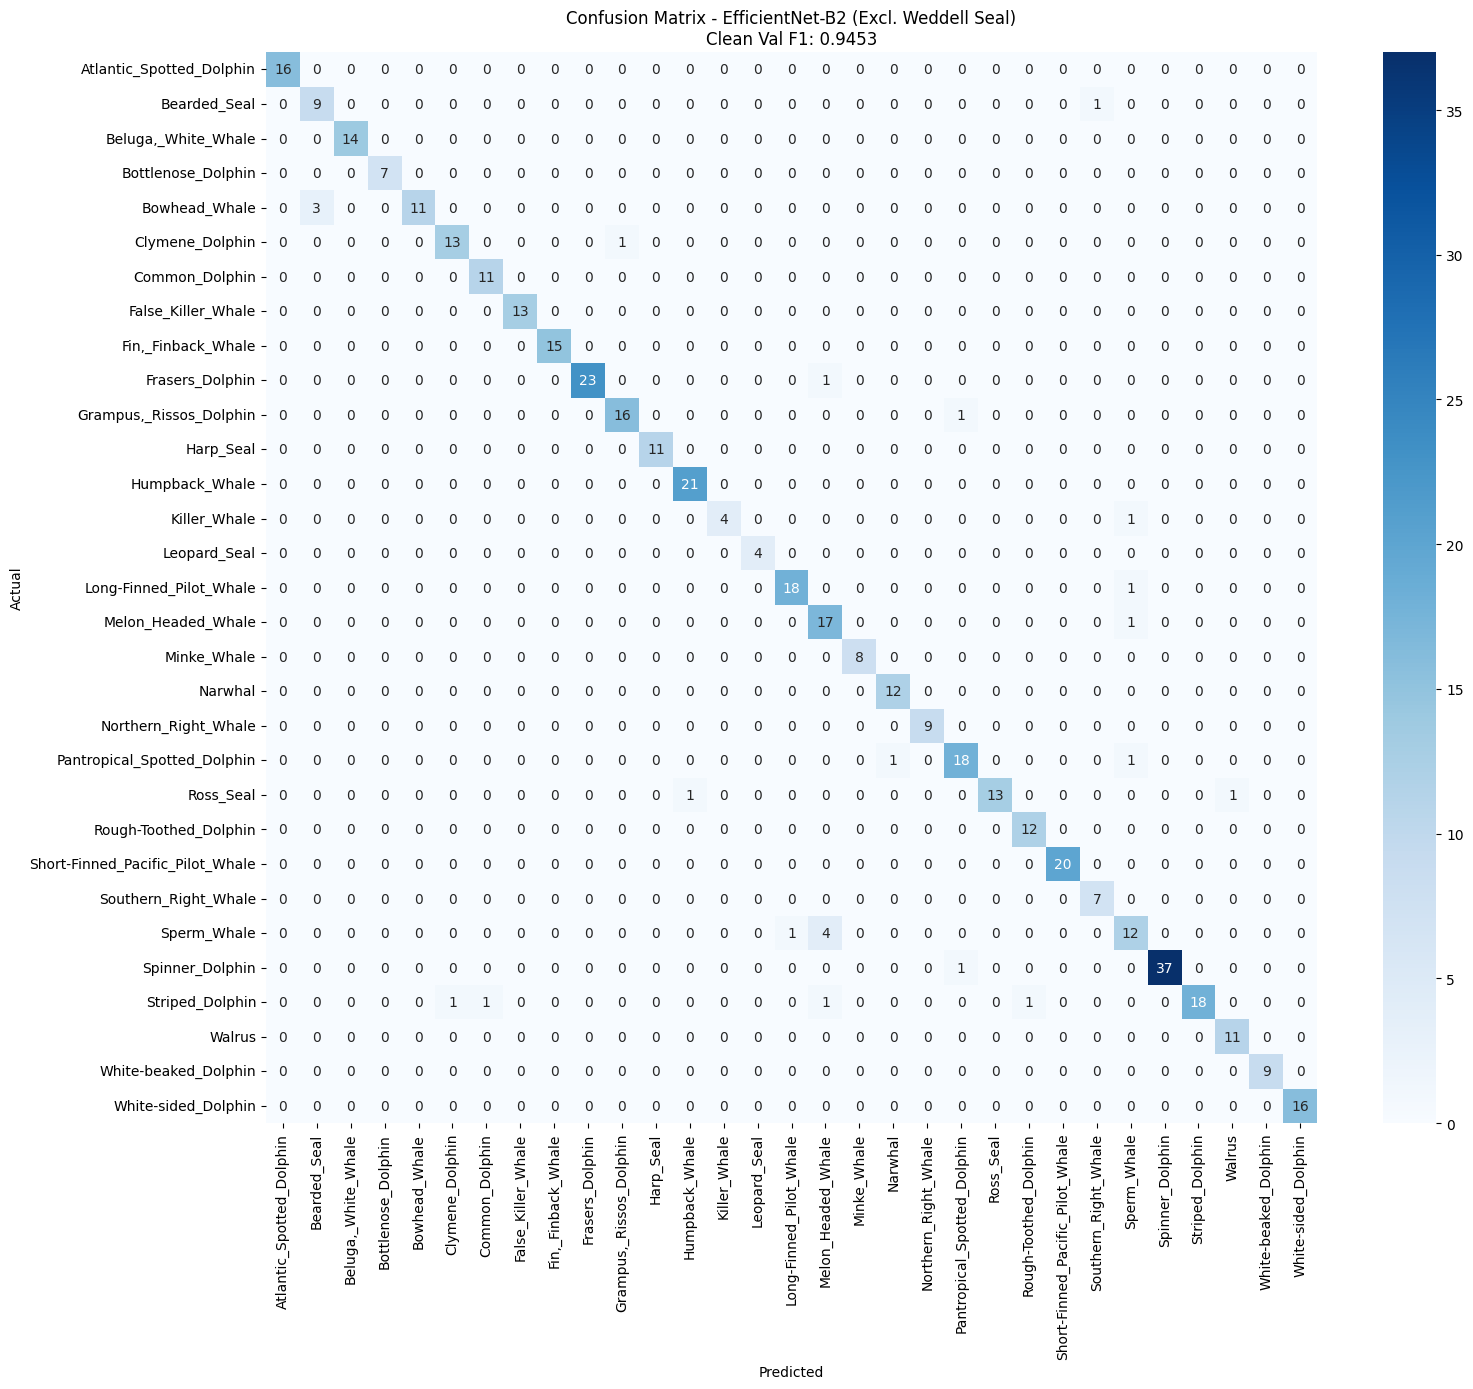


Detailed Classification Report (Excluding Weddell_Seal):
                                  precision    recall  f1-score   support

        Atlantic_Spotted_Dolphin       1.00      1.00      1.00        16
                    Bearded_Seal       0.69      0.90      0.78        10
             Beluga,_White_Whale       1.00      1.00      1.00        14
              Bottlenose_Dolphin       1.00      1.00      1.00         7
                   Bowhead_Whale       1.00      0.79      0.88        14
                 Clymene_Dolphin       0.93      0.87      0.90        15
                  Common_Dolphin       0.92      1.00      0.96        11
              False_Killer_Whale       1.00      1.00      1.00        13
              Fin,_Finback_Whale       1.00      1.00      1.00        15
                 Frasers_Dolphin       1.00      0.96      0.98        24
         Grampus,_Rissos_Dolphin       0.94      0.94      0.94        17
                       Harp_Seal       1.00      1.00

In [7]:
# ==========================================
# 6. EVALUATION VISUALIZATION (EXCLUDING WEDDELL SEAL)
# ==========================================

# 1. Identifikasi Index yang akan ditampilkan (Exclude Weddell_Seal)
WEDDELL_ID = label2id.get('Weddell_Seal', -1)

if WEDDELL_ID != -1:
    # Ambil semua index KECUALI index Weddell Seal
    display_indices = [i for i in range(len(classes)) if i != WEDDELL_ID]
    # Ambil nama kelas yang sesuai dengan index tersebut
    display_classes = [classes[i] for i in display_indices]
    print(f"⚠️ Visualization Info: 'Weddell_Seal' (ID: {WEDDELL_ID}) has been removed from Confusion Matrix & Report.")
else:
    display_indices = list(range(len(classes)))
    display_classes = classes

# 2. Generate Confusion Matrix hanya untuk kelas yang dipilih
# Parameter 'labels' memaksa sklearn hanya menghitung/menampilkan index yang kita mau
cm = confusion_matrix(best_targets, best_preds, labels=display_indices)

# Normalize (Optional: jika ingin melihat persentase)
cm_norm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
cm_norm = np.nan_to_num(cm_norm)

# 3. Plotting
plt.figure(figsize=(16, 14))
# Menggunakan 'cm' untuk raw counts, ganti ke 'cm_norm' jika ingin melihat persentase 0.0-1.0
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
            xticklabels=display_classes, 
            yticklabels=display_classes)

plt.title(f"Confusion Matrix - EfficientNet-B2 (Excl. Weddell Seal)\nClean Val F1: {best_f1:.4f}")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

# 4. Classification Report (Hanya kelas yang dipilih)
print("\nDetailed Classification Report (Excluding Weddell_Seal):")
print(classification_report(
    best_targets, 
    best_preds, 
    labels=display_indices,       # Hanya hitung index ini
    target_names=display_classes, # Pakai nama kelas yang sudah difilter
    zero_division=0
))

In [24]:
# ==================================================================================
# OPTIMASI F1: SOFT VOTING ENSEMBLE (Model + Anchor)
# ==================================================================================

import torch
import torch.nn.functional as F
import numpy as np
from sklearn.metrics import f1_score, classification_report

def get_combined_predictions(model, val_loader, anchor_vector, device, label2id, alpha=0.7):
    """
    alpha: Seberapa besar kita percaya sama Model? (0.0 - 1.0)
           alpha 0.7 berarti 70% percaya model, 30% percaya similarity anchor.
    """
    model.eval()
    WEDDELL_ID = label2id['Weddell_Seal']
    
    all_preds = []
    all_labels = []
    
    with torch.no_grad():
        for inputs, labels in val_loader:
            inputs = inputs.to(device)
            
            # 1. Skor dari Model (Softmax Probabilities)
            logits = model(inputs)
            probs_model = torch.softmax(logits, dim=1) # Shape: [Batch, 31]
            
            # 2. Skor dari Similarity (Anchor)
            # Kita perlu bikin matriks similarity untuk SEMUA kelas.
            # Trik: Untuk kelas selain Weddell, kita anggap similarity-nya 0 (netral) 
            # atau sama dengan probs model agar tidak ganggu.
            
            features = get_features(model, inputs) # Pakai helper function yg tadi
            features_norm = F.normalize(features, p=2, dim=1)
            anchor_norm = F.normalize(anchor_vector.unsqueeze(0), p=2, dim=1)
            
            # Hitung kemiripan dengan Weddell Seal
            sim_weddell = torch.mm(features_norm, anchor_norm.t()) # Shape: [Batch, 1]
            
            # Normalisasi similarity jadi 0-1 (karena cosine range -1 s/d 1)
            sim_weddell = (sim_weddell + 1) / 2 
            
            # 3. GABUNGKAN SKOR (Ensemble)
            # Kita hanya 'mengganggu' kolom Weddell Seal. Kelas lain biarkan murni model.
            
            final_probs = probs_model.clone()
            
            # Logika Pembobotan Khusus Weddell Seal:
            # New_Weddell_Prob = (Old_Prob * alpha) + (Similarity * (1-alpha))
            
            current_weddell_prob = probs_model[:, WEDDELL_ID].unsqueeze(1)
            
            # HANYA update probabilitas Weddell Seal
            # Jika similarity tinggi, probabilitas Weddell naik.
            # Jika similarity rendah, probabilitas Weddell turun (terhukum).
            new_weddell_prob = (current_weddell_prob * alpha) + (sim_weddell * (1 - alpha))
            
            final_probs[:, WEDDELL_ID] = new_weddell_prob.squeeze(1)
            
            # Ambil pemenang (Argmax) dari probabilitas baru
            preds = torch.argmax(final_probs, dim=1)
            
            all_preds.extend(preds.cpu().numpy())
            all_labels.extend(labels.numpy())
            
    return np.array(all_labels), np.array(all_preds)

# --- PENCARIAN HYPERPARAMETER OTOMATIS (Grid Search Alpha) ---
def find_best_alpha(model, val_loader, anchor_vec, device, label2id):
    print("⚙️ Sedang mencari 'alpha' (keseimbangan) terbaik...")
    
    best_f1 = 0
    best_alpha = 0
    
    # Coba alpha dari 0.5 sampai 1.0 (langkah 0.05)
    # 1.0 artinya 100% pakai model lama (skor 0.95)
    alphas = np.arange(0.5, 1.01, 0.05)
    
    results = []
    
    for a in tqdm(alphas, desc="Tuning Alpha"):
        y_true, y_pred = get_combined_predictions(model, val_loader, anchor_vec, device, label2id, alpha=a)
        
        # Hitung F1 Macro (Termasuk Weddell Seal)
        score = f1_score(y_true, y_pred, average='macro')
        results.append((a, score))
        
        if score > best_f1:
            best_f1 = score
            best_alpha = a
            
    print(f"\n🏆 Alpha Terbaik: {best_alpha:.2f}")
    print(f"📈 F1 Macro Tertinggi: {best_f1:.5f}")
    
    return best_alpha

# ==================================================
# EKSEKUSI
# ==================================================

if anchor_vec is not None:
    # 1. Cari Alpha Terbaik
    best_alpha = find_best_alpha(model, val_loader, anchor_vec, CFG['device'], label2id)
    
    # 2. Tampilkan Laporan Final dengan Alpha Terbaik
    print(f"\n📄 FINAL OPTIMIZED REPORT (Alpha={best_alpha:.2f}):")
    y_true, y_pred_opt = get_combined_predictions(model, val_loader, anchor_vec, CFG['device'], label2id, alpha=best_alpha)
    
    target_names = [k for k, v in sorted(label2id.items(), key=lambda item: item[1])]
    print(classification_report(y_true, y_pred_opt, target_names=target_names))
    
    # 3. Simpan Perbandingan (Optional)
    # Cek apakah kita berhasil mengalahkan base model (alpha=1.0)
    # Jika alpha terbaik < 1.0, berarti strategi hybrid berhasil meningkatkan skor!

⚙️ Sedang mencari 'alpha' (keseimbangan) terbaik...


Tuning Alpha:   0%|          | 0/11 [00:00<?, ?it/s]


🏆 Alpha Terbaik: 0.85
📈 F1 Macro Tertinggi: 0.91742

📄 FINAL OPTIMIZED REPORT (Alpha=0.85):
                                  precision    recall  f1-score   support

        Atlantic_Spotted_Dolphin       1.00      1.00      1.00        16
                    Bearded_Seal       0.69      0.90      0.78        10
             Beluga,_White_Whale       1.00      1.00      1.00        14
              Bottlenose_Dolphin       1.00      1.00      1.00         7
                   Bowhead_Whale       1.00      0.79      0.88        14
                 Clymene_Dolphin       1.00      0.93      0.97        15
                  Common_Dolphin       0.92      1.00      0.96        11
              False_Killer_Whale       1.00      1.00      1.00        13
              Fin,_Finback_Whale       1.00      1.00      1.00        15
                 Frasers_Dolphin       1.00      0.92      0.96        24
         Grampus,_Rissos_Dolphin       1.00      0.88      0.94        17
                  

🔍 Menganalisis Dampak Soft Voting (Alpha=0.85) pada 30 Kelas Lain...

📊 REPORT PERBANDINGAN (APPLE-TO-APPLE vs MODEL 0.95):
                                  precision    recall  f1-score   support

        Atlantic_Spotted_Dolphin       1.00      1.00      1.00        16
                    Bearded_Seal       0.75      0.90      0.82        10
             Beluga,_White_Whale       1.00      1.00      1.00        14
              Bottlenose_Dolphin       1.00      1.00      1.00         7
                   Bowhead_Whale       1.00      0.79      0.88        14
                 Clymene_Dolphin       1.00      0.93      0.97        15
                  Common_Dolphin       0.92      1.00      0.96        11
              False_Killer_Whale       1.00      1.00      1.00        13
              Fin,_Finback_Whale       1.00      1.00      1.00        15
                 Frasers_Dolphin       1.00      0.92      0.96        24
         Grampus,_Rissos_Dolphin       1.00      0.88      0.

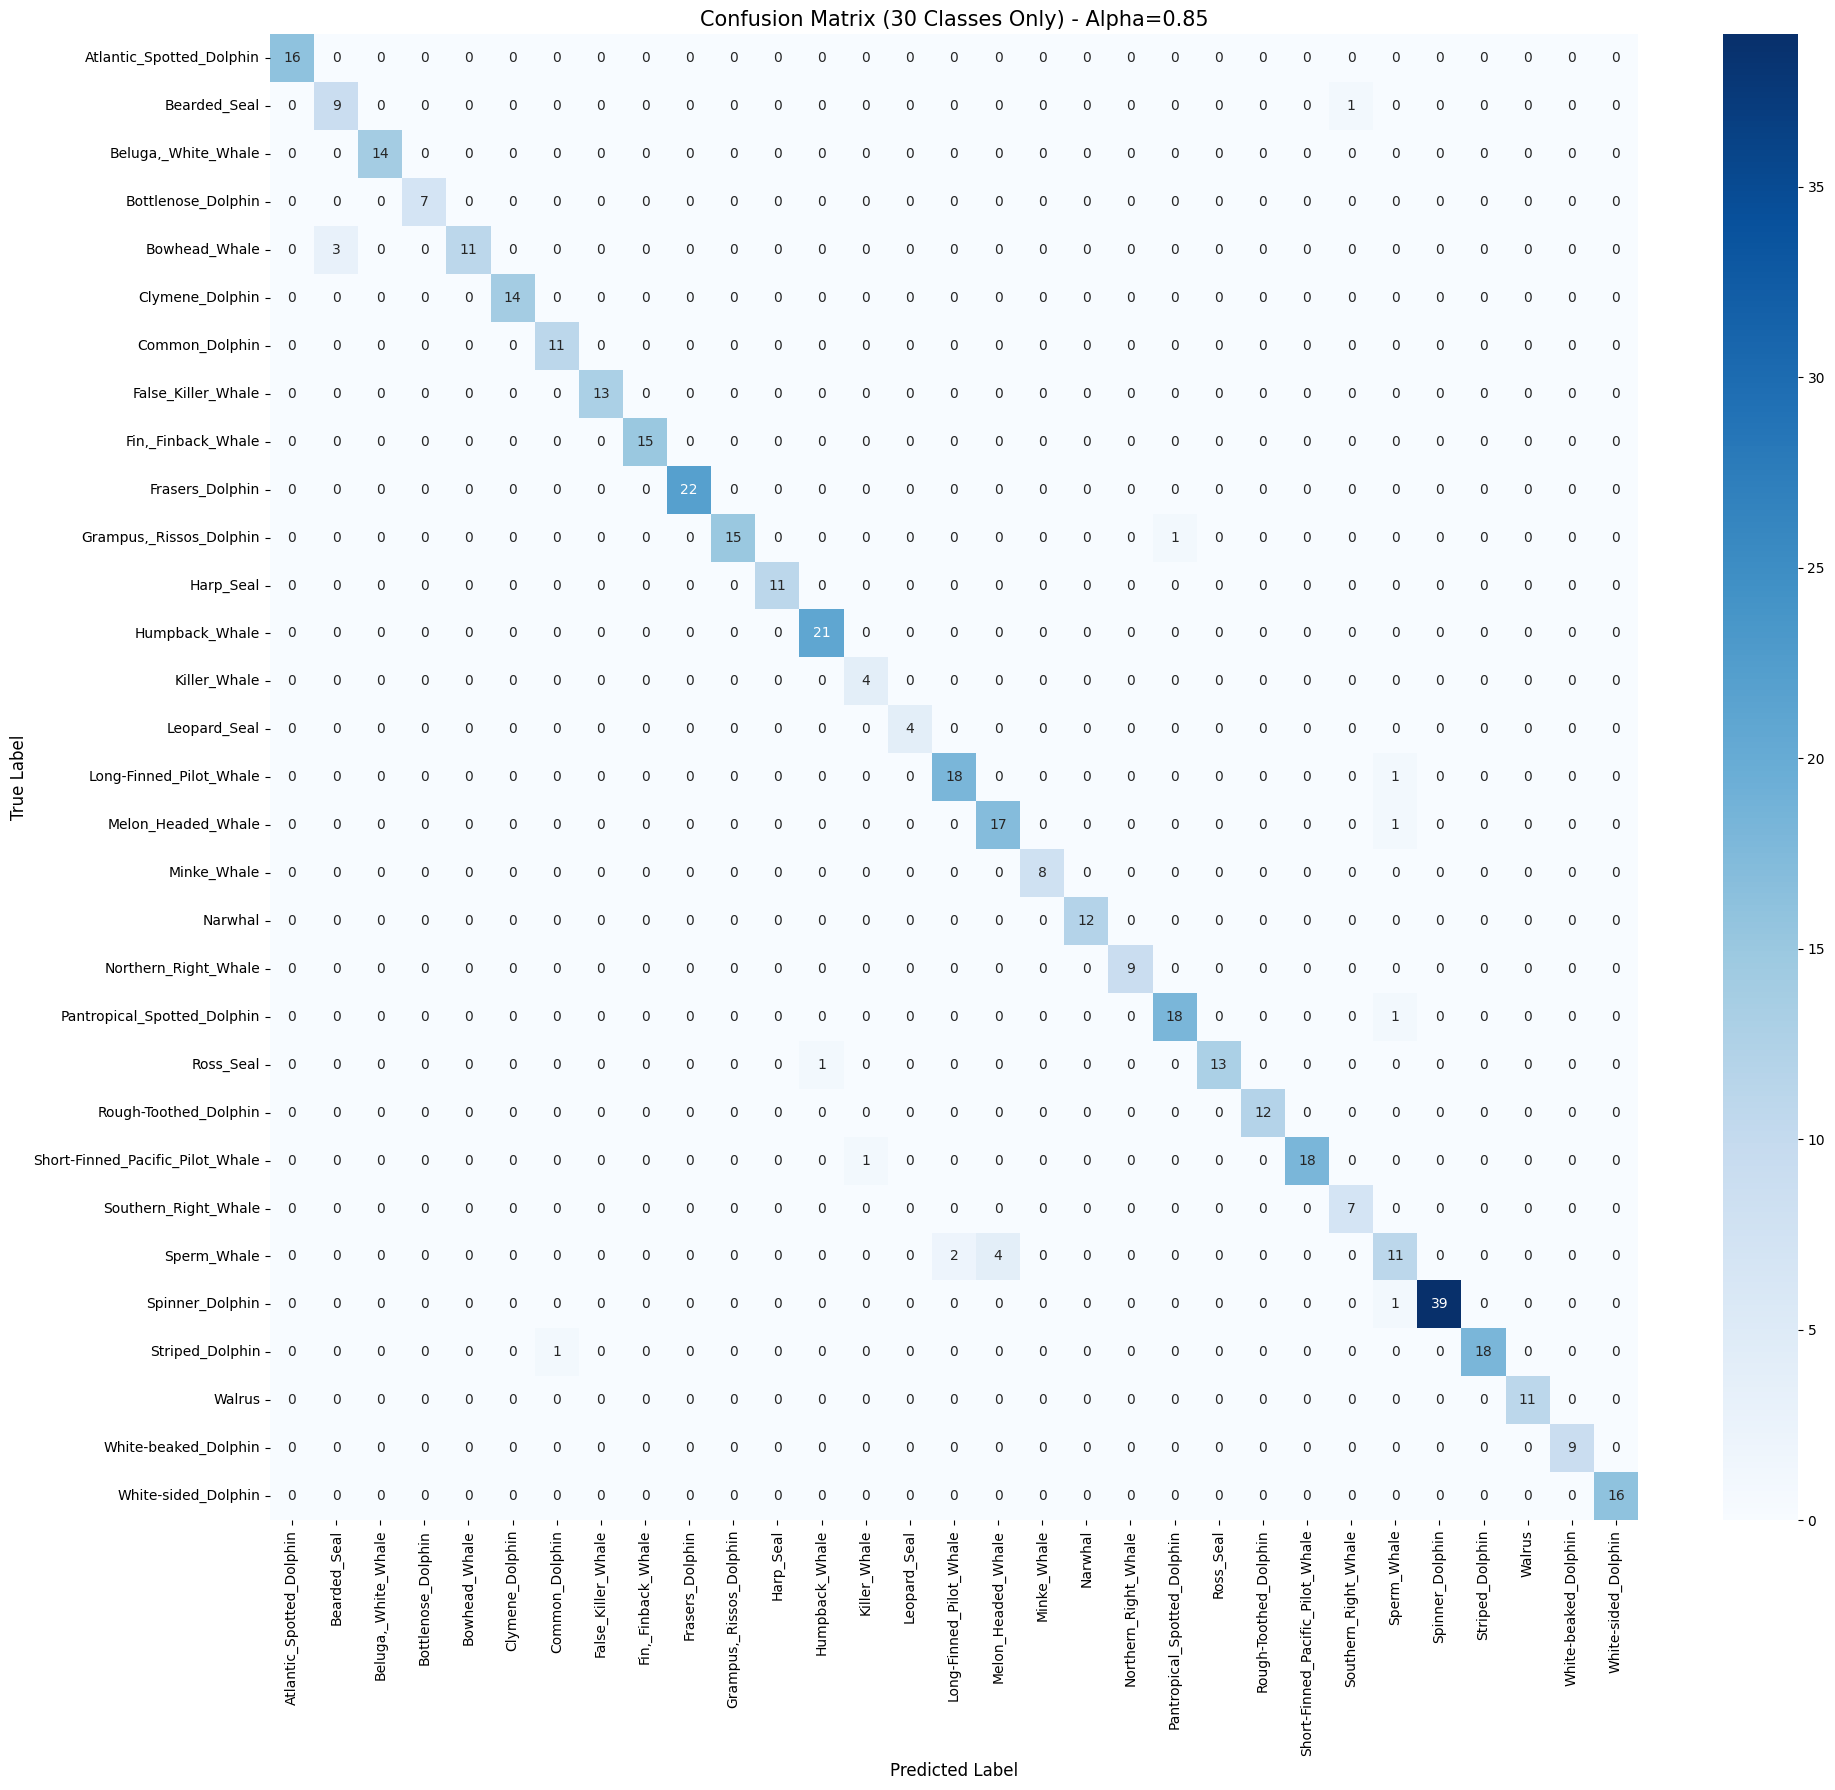

In [28]:
# ==================================================================================
# FIXED: FINAL CHECK & VISUALIZATION (EXCLUDING WEDDELL SEAL PROPERLY)
# ==================================================================================

import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import classification_report, confusion_matrix

# Pastikan variabel ini tersedia dari cell sebelumnya
if 'best_alpha' in globals() and 'y_pred_opt' in globals():

    print(f"🔍 Menganalisis Dampak Soft Voting (Alpha={best_alpha:.2f}) pada 30 Kelas Lain...\n")
    
    # 1. Ambil ID Weddell Seal
    WEDDELL_ID = label2id['Weddell_Seal']
    
    # 2. FILTER Y_TRUE: Hapus sampel yang aslinya memang Weddell Seal
    # (Kita tidak ingin menilai kemampuan model mengenali Weddell asli di report ini)
    mask_valid = y_true != WEDDELL_ID 
    y_true_filtered = y_true[mask_valid]
    y_pred_filtered = y_pred_opt[mask_valid] # Ambil prediksi untuk sampel non-Weddell saja
    
    # 3. SETUP LABEL & NAMA (Hanya 30 Kelas)
    # Kita urutkan berdasarkan ID agar mappingnya benar
    sorted_labels = sorted(label2id.items(), key=lambda item: item[1])
    
    # Ambil ID dan Nama untuk SEMUA KELAS KECUALI Weddell Seal
    valid_ids = [v for k, v in sorted_labels if k != 'Weddell_Seal']
    valid_names = [k for k, v in sorted_labels if k != 'Weddell_Seal']
    
    # 4. CLASSIFICATION REPORT (Dengan Parameter 'labels')
    # labels=valid_ids memberitahu sklearn untuk HANYA membuat baris bagi 30 kelas tersebut.
    # Jika model memprediksi Weddell Seal (False Positive), itu tetap dihitung sebagai salah (False Negative bagi kelas aslinya),
    # tapi kolom Weddell Seal-nya tidak ditampilkan.
    
    print("📊 REPORT PERBANDINGAN (APPLE-TO-APPLE vs MODEL 0.95):")
    print(classification_report(y_true_filtered, y_pred_filtered, labels=valid_ids, target_names=valid_names))
    
    # 5. CONFUSION MATRIX (30x30)
    # Kita juga membatasi CM hanya pada 30 kelas
    cm = confusion_matrix(y_true_filtered, y_pred_filtered, labels=valid_ids)
    
    plt.figure(figsize=(20, 18))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=valid_names,
                yticklabels=valid_names)

    plt.title(f'Confusion Matrix (30 Classes Only) - Alpha={best_alpha:.2f}', fontsize=15)
    plt.ylabel('True Label', fontsize=12)
    plt.xlabel('Predicted Label', fontsize=12)
    plt.xticks(rotation=90)
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

else:
    print("⚠️ Variabel prediksi (y_pred_opt) belum ada. Jalankan cell Soft Voting di atas dulu.")